# Churn Prediction Inteligente – Telco Customer Churn
### Proyecto Final #1 – Minería de Datos · Metodología CRISP-DM

**Grupo 6:** Luis Mario Chamizo Tiafi · Juan Diego Chamizo Tiafi

**Objetivo general:** desarrollar un modelo predictivo basado en técnicas de *machine learning* que permita identificar clientes con alta probabilidad de abandono, integrando análisis de comportamiento y explicabilidad del modelo para diseñar estrategias de retención personalizadas.

| Fase CRISP-DM | Sección del notebook |
|---|---|
| 1. Comprensión del negocio | §1 |
| 2. Comprensión de los datos | §2 (EDA, calidad, pruebas estadísticas) |
| 3. Preparación de los datos | §3 (limpieza, *feature engineering* RFM, partición) |
| 4. Modelado | §4 (LR, Random Forest, XGBoost, LightGBM, MLP + Stacking) |
| 5. Evaluación | §5 (Accuracy, F1, ROC-AUC, umbral, valor de negocio, SHAP) |
| 6. Despliegue | §6 (artefactos para la aplicación web Streamlit) |

# 1. Comprensión del negocio

**Contexto.** En telecomunicaciones, adquirir un cliente nuevo es mucho más costoso que retener uno existente, y pequeñas mejoras en la retención producen aumentos importantes en la rentabilidad (Reichheld y Sasser, 1990). El *churn* (abandono) reduce los ingresos recurrentes y el valor de vida del cliente (CLV). La empresa necesita anticipar qué clientes van a cancelar **antes** de que lo hagan, para actuar con campañas de retención focalizadas.

**Objetivos de negocio**
1. Identificar a los clientes con alta probabilidad de abandono.
2. Entender **por qué** se van (factores de comportamiento, contrato, servicios, facturación).
3. Priorizar la inversión de retención según **riesgo × valor** del cliente.
4. Proponer acciones de retención **personalizadas** para cada cliente.

**Objetivos de minería de datos**
- Clasificación binaria supervisada: `Churn ∈ {0, 1}`.
- Comparar al menos 5 algoritmos: Regresión Logística, Random Forest (*bagging*), XGBoost (*boosting*), LightGBM y Red Neuronal (MLP).
- Explicar las predicciones global y localmente con **SHAP**.

**Criterios de éxito**
| Tipo | Criterio |
|---|---|
| Minería de datos | ROC-AUC ≥ 0.84 en el conjunto de prueba; Recall de la clase *churn* ≥ 0.70 con el umbral elegido |
| Negocio | Contactando al 30 % de clientes con mayor riesgo se captura ≥ 60 % de los que abandonan (*lift* ≥ 2) |
| Despliegue | Aplicación web con predicción individual / por lotes, dashboard de riesgo y recomendaciones |

**Recursos y supuestos:** dataset público *Telco Customer Churn* (IBM, Kaggle), Python 3, scikit-learn, XGBoost, LightGBM, SHAP y Streamlit. Supuestos económicos para la evaluación de negocio (§5.6): costo de contacto + incentivo = USD 50 por cliente, tasa de éxito de la retención = 35 %, valor de un cliente retenido = 12 meses de su cargo mensual.

In [1]:
# =====================================================
# LIBRERÍAS PRINCIPALES
# =====================================================
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             classification_report)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap, joblib, sklearn, xgboost, lightgbm

warnings.filterwarnings("ignore")

# Rutas del proyecto
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"; MODELS = ROOT / "models"; FIG = ROOT / "reports" / "figures"; REP = ROOT / "reports"
for p in (MODELS, FIG): p.mkdir(parents=True, exist_ok=True)

# Módulo propio con limpieza, feature engineering RFM y recomendaciones
from features import *

SEED = 42
np.random.seed(SEED)

# Paleta validada (CVD-safe) usada en todos los gráficos
C_NO, C_SI = "#2a78d6", "#eb6834"                     # No abandona / Abandona
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.axisbelow": True,
})
def savefig(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| lightgbm", lightgbm.__version__, "| shap", shap.__version__)

C:\Users\luism\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | shap 0.54.1


# 2. Comprensión de los datos
## 2.1 Recolección y descripción inicial
El dataset *Telco Customer Churn* contiene 7 043 clientes y 21 columnas: datos demográficos, servicios contratados, información de la cuenta y la variable objetivo `Churn` (si el cliente abandonó en el último mes).

In [2]:
# =====================================================
# CARGAR DATASET
# =====================================================
df_raw = pd.read_csv(DATA / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dimensiones:", df_raw.shape)
df_raw.head()

Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Diccionario de datos
dicc = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "valores_unicos": df_raw.nunique(),
    "ejemplo": df_raw.iloc[0],
})
dicc["descripcion"] = dicc.index.map(lambda c: FEATURE_LABELS.get(c, {"customerID": "Identificador del cliente", "Churn": "Abandonó (Yes/No) – OBJETIVO"}.get(c, "")))
dicc

,tipo,valores_unicos,ejemplo,descripcion
customerID,str,7043,7590-VHVEG,Identificador del cliente
gender,str,2,Female,Género
SeniorCitizen,int64,2,0,Adulto mayor
Partner,str,2,Yes,Tiene pareja
Dependents,str,2,No,Tiene dependientes
tenure,int64,73,1,Antigüedad (meses)
PhoneService,str,2,No,Servicio telefónico
MultipleLines,str,3,No phone service,Múltiples líneas
InternetService,str,3,DSL,Tipo de internet
OnlineSecurity,str,3,No,Seguridad en línea


## 2.2 Verificación de la calidad de los datos

In [4]:
# =====================================================
# CALIDAD DE DATOS
# =====================================================
calidad = pd.DataFrame({
    "nulos": df_raw.isnull().sum(),
    "vacios_texto": df_raw.apply(lambda s: (s.astype(str).str.strip() == "").sum()),
})
print("Filas duplicadas:", df_raw.duplicated().sum())
print("IDs duplicados:", df_raw["customerID"].duplicated().sum())
print("\nTotalCharges es de tipo texto:", df_raw["TotalCharges"].dtype)
print("Registros con TotalCharges vacío:", (df_raw["TotalCharges"].astype(str).str.strip() == "").sum())
print("Tenure de esos registros:", df_raw.loc[df_raw["TotalCharges"].astype(str).str.strip() == "", "tenure"].unique())
calidad[calidad.sum(axis=1) > 0]

Filas duplicadas: 0
IDs duplicados: 0

TotalCharges es de tipo texto: str
Registros con TotalCharges vacío: 11
Tenure de esos registros: [0]


,nulos,vacios_texto
TotalCharges,0,11


**Hallazgos de calidad**
- No hay valores nulos explícitos ni filas o IDs duplicados.
- `TotalCharges` está almacenado como texto y tiene **11 espacios en blanco**. Todos son clientes con `tenure = 0`, es decir, clientes recién incorporados que todavía no han recibido factura. No es un dato perdido al azar: el valor correcto es 0 (se imputa como `MonthlyCharges × tenure = 0`).
- `SeniorCitizen` viene codificada como 0/1, a diferencia del resto de variables binarias (Yes/No).

In [5]:
df = clean_raw(df_raw)       # limpieza (ver src/features.py)
df[RAW_NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


## 2.3 Exploración de los datos (EDA)

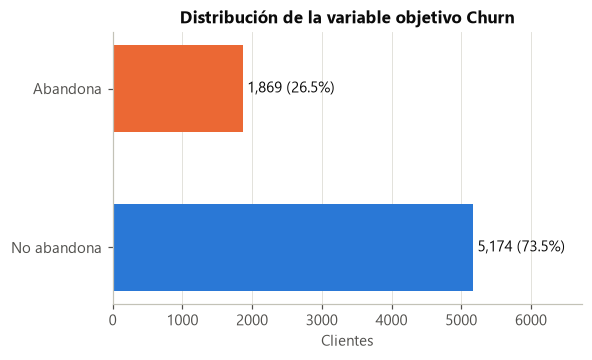

Tasa de churn: 26.54% → clases desbalanceadas (~1:2.8)


In [6]:
# =====================================================
# DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# =====================================================
conteo = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.barh(["No abandona", "Abandona"], conteo.values, color=[C_NO, C_SI], height=0.55)
for b, v in zip(bars, conteo.values):
    ax.text(v + 60, b.get_y() + b.get_height() / 2, f"{v:,} ({v / len(df):.1%})", va="center", color=INK)
ax.set_xlim(0, conteo.max() * 1.3); ax.set_xlabel("Clientes"); ax.grid(axis="y", visible=False)
ax.set_title("Distribución de la variable objetivo Churn")
savefig("01_distribucion_churn")
print(f"Tasa de churn: {df[TARGET].mean():.2%} → clases desbalanceadas (~1:2.8)")

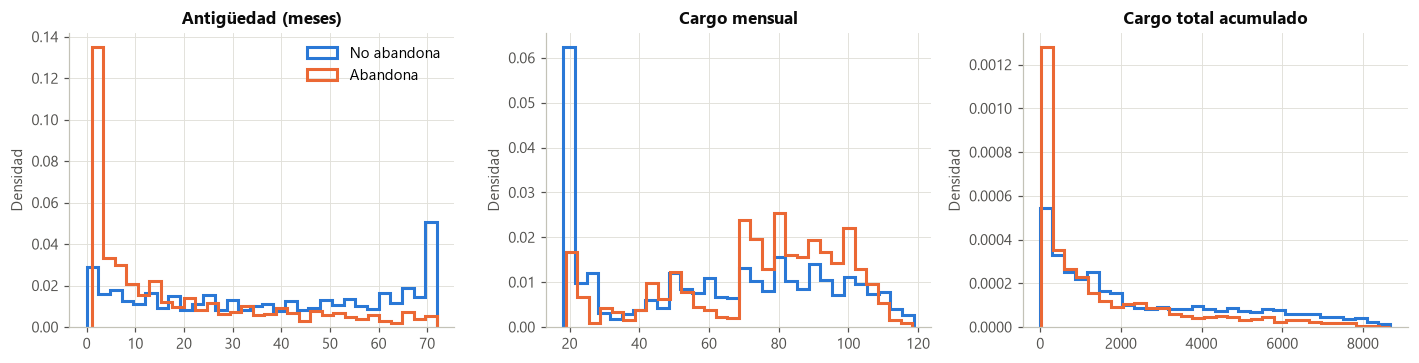

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No abandona,38.0,64.425,1679.525
Abandona,10.0,79.650,703.550


In [7]:
# =====================================================
# VARIABLES NUMÉRICAS SEGÚN CHURN
# =====================================================
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for val, color, lab in [(0, C_NO, "No abandona"), (1, C_SI, "Abandona")]:
        ax.hist(df.loc[df[TARGET] == val, col], bins=30, density=True, histtype="step",
                linewidth=2, color=color, label=lab)
    ax.set_title(FEATURE_LABELS[col]); ax.set_ylabel("Densidad")
axes[0].legend()
plt.tight_layout(); savefig("02_numericas_vs_churn")
df.groupby(TARGET)[["tenure", "MonthlyCharges", "TotalCharges"]].median().rename(index={0: "No abandona", 1: "Abandona"})

Los clientes que abandonan tienen una **antigüedad mucho menor** (mediana de 10 meses frente a 38) y **cargos mensuales más altos** (USD 79.6 frente a 64.4). El cargo total acumulado es menor porque llevan menos tiempo en la empresa.

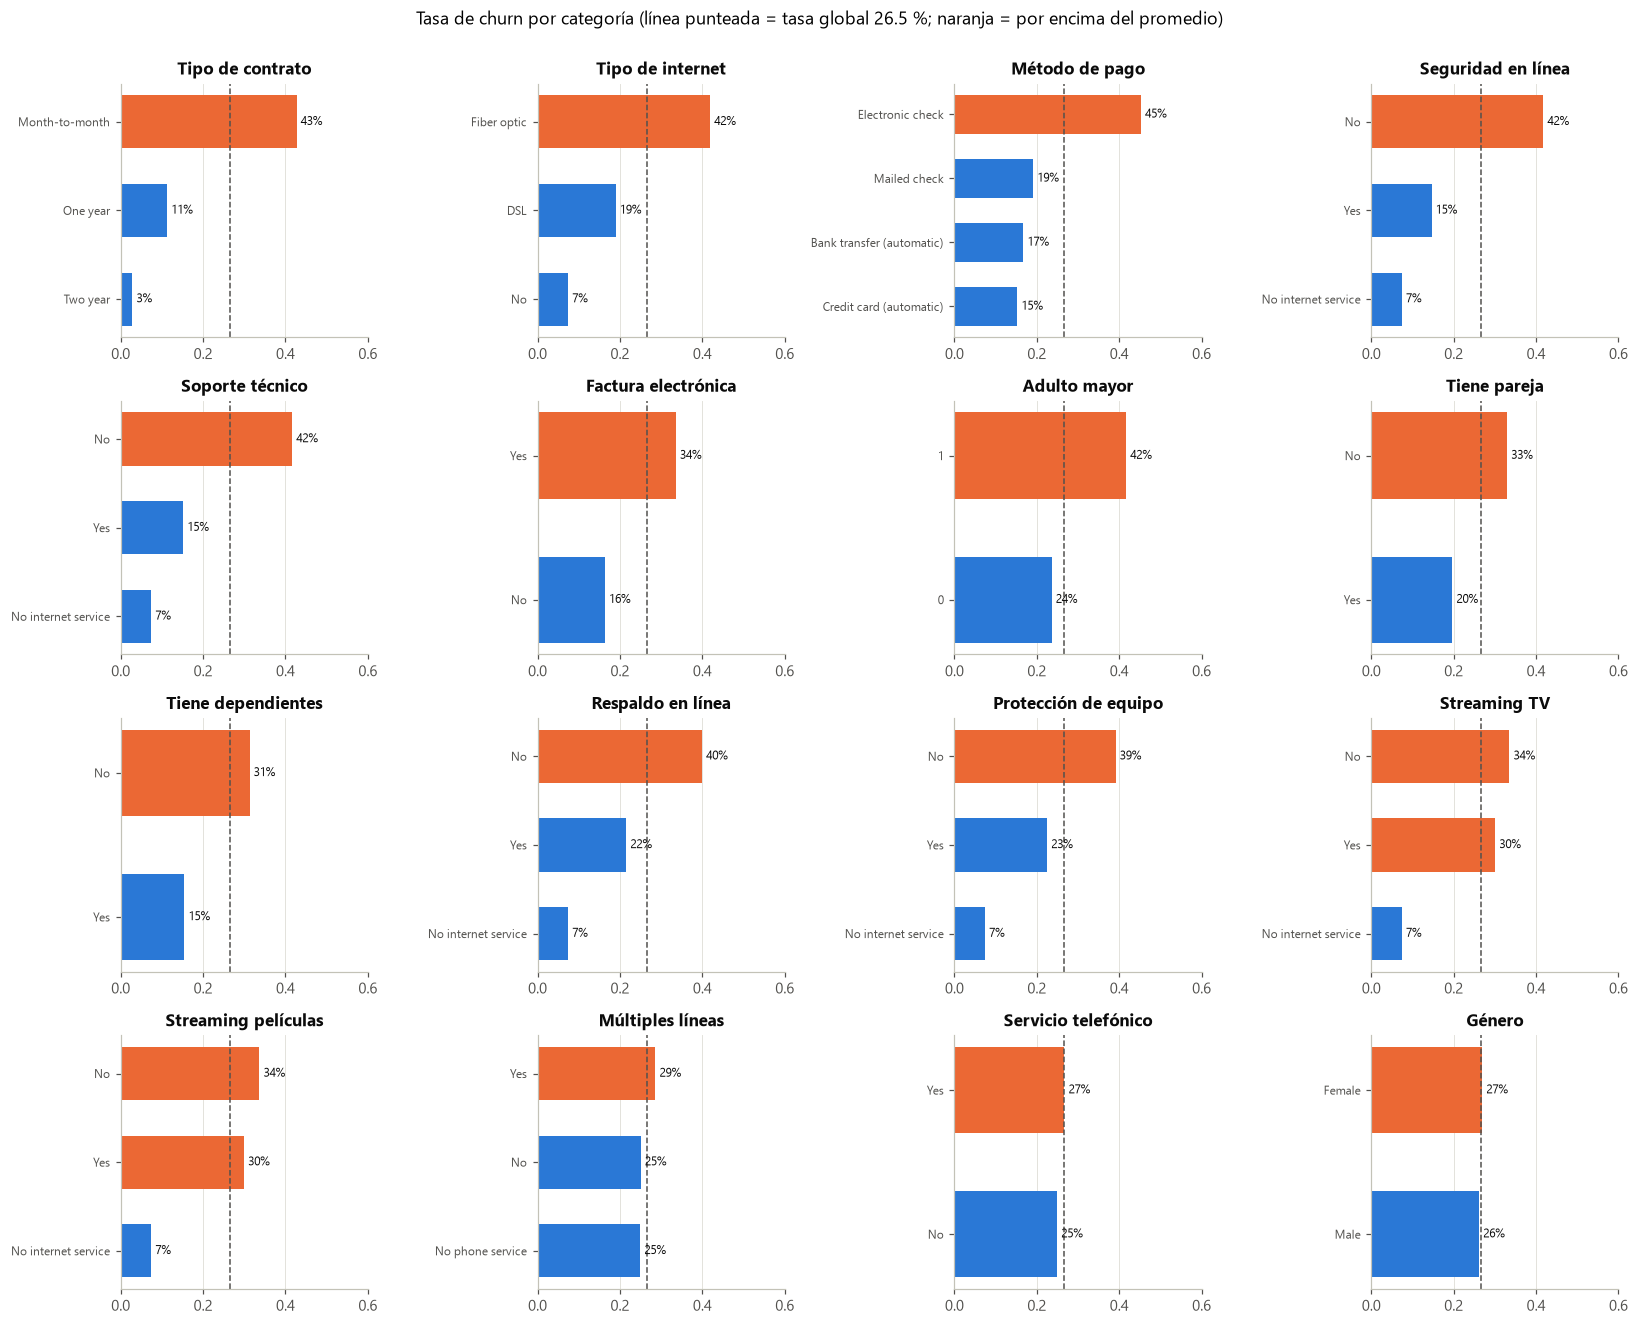

In [8]:
# =====================================================
# TASA DE CHURN POR VARIABLE CATEGÓRICA
# =====================================================
cat_plot = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport",
            "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "OnlineBackup",
            "DeviceProtection", "StreamingTV", "StreamingMovies", "MultipleLines", "PhoneService", "gender"]
tasa_global = df[TARGET].mean()
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, col in zip(axes.ravel(), cat_plot):
    t = df.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(t.index.astype(str), t["mean"], color=[C_SI if m > tasa_global else C_NO for m in t["mean"]], height=0.6)
    ax.axvline(tasa_global, color=INK2, linestyle="--", linewidth=1)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(m + 0.01, i, f"{m:.0%}", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, 0.6); ax.set_title(FEATURE_LABELS.get(col, col)); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Tasa de churn por categoría (línea punteada = tasa global 26.5 %; naranja = por encima del promedio)", y=1.0, fontsize=12)
plt.tight_layout(); savefig("03_tasa_churn_categoricas")

**Patrones de comportamiento identificados**
- **Contrato mes a mes:** 42.7 % de churn frente a 11.3 % (1 año) y 2.8 % (2 años). Es el factor más fuerte.
- **Fibra óptica:** 41.9 % de churn. Paga más y posiblemente está menos satisfecha con la relación precio/calidad.
- **Pago con cheque electrónico:** 45.3 %, frente a cerca del 16 % con pago automático.
- **Sin Seguridad en línea ni Soporte técnico:** alrededor del 42 % de churn. Los servicios de protección generan vínculo.
- **Adultos mayores** (41.7 %) y clientes **sin pareja ni dependientes** abandonan más.
- **Género** y **servicio telefónico** prácticamente no tienen relación con el churn.

In [9]:
# =====================================================
# PRUEBAS ESTADÍSTICAS DE ASOCIACIÓN
# Chi-cuadrado + V de Cramér (categóricas) y Mann-Whitney U (numéricas)
# =====================================================
filas = []
for col in RAW_CATEGORICAL + ["SeniorCitizen"]:
    tabla = pd.crosstab(df[col], df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append({"variable": col, "prueba": "Chi-cuadrado", "estadistico": chi2, "p_valor": p, "efecto": v, "medida": "V de Cramér"})
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    a, b = df.loc[df[TARGET] == 1, col], df.loc[df[TARGET] == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    filas.append({"variable": col, "prueba": "Mann-Whitney U", "estadistico": u, "p_valor": p,
                  "efecto": abs(1 - 2 * u / (len(a) * len(b))), "medida": "r biserial (rango)"})
asociacion = pd.DataFrame(filas).sort_values("efecto", ascending=False).reset_index(drop=True)
asociacion["significativa (α=0.05)"] = asociacion["p_valor"] < 0.05
asociacion.to_csv(REP / "pruebas_asociacion.csv", index=False)
asociacion.round(4)

,variable,prueba,estadistico,p_valor,efecto,medida,significativa (α=0.05)
0,tenure,Mann-Whitney U,2.515538e+06,0.0000,0.4797,r biserial (rango),True
1,Contract,Chi-cuadrado,1.184597e+03,0.0000,0.4101,V de Cramér,True
2,OnlineSecurity,Chi-cuadrado,8.499990e+02,0.0000,0.3474,V de Cramér,True
3,TechSupport,Chi-cuadrado,8.281971e+02,0.0000,0.3429,V de Cramér,True
4,InternetService,Chi-cuadrado,7.323096e+02,0.0000,0.3225,V de Cramér,True
5,PaymentMethod,Chi-cuadrado,6.481423e+02,0.0000,0.3034,V de Cramér,True
6,TotalCharges,Mann-Whitney U,3.381224e+06,0.0000,0.3007,r biserial (rango),True
7,OnlineBackup,Chi-cuadrado,6.018128e+02,0.0000,0.2923,V de Cramér,True
8,DeviceProtection,Chi-cuadrado,5.584194e+02,0.0000,0.2816,V de Cramér,True
9,MonthlyCharges,Mann-Whitney U,6.003126e+06,0.0000,0.2416,r biserial (rango),True


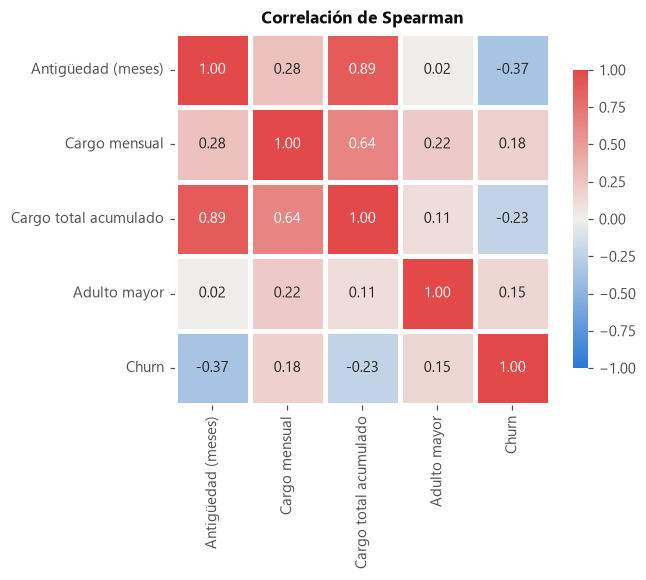

In [10]:
# Correlación entre variables numéricas (incluida la objetivo)
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", TARGET]].corr(method="spearman")
cmap_div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(5.5, 4.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap_div, vmin=-1, vmax=1, linewidths=2, linecolor="white",
            xticklabels=[FEATURE_LABELS.get(c, c) for c in corr.columns],
            yticklabels=[FEATURE_LABELS.get(c, c) for c in corr.columns], ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlación de Spearman"); savefig("04_correlacion")

`TotalCharges` está fuertemente correlacionada con `tenure` (ρ ≈ 0.89), porque es aproximadamente antigüedad × cargo mensual. Esta redundancia se conserva para los modelos de árboles, y la Regresión Logística la controla con regularización. Además motiva la variable derivada `GastoPromedioMensual`.

# 3. Preparación de los datos
## 3.1 Limpieza
Implementada en `src/features.py → clean_raw()`:
- `TotalCharges` se convierte a numérico y los 11 vacíos se imputan con 0 (`tenure = 0`).
- Se eliminan espacios en las columnas de texto y `Churn` se convierte a 0/1.
- `customerID` se excluye del modelado (es un identificador sin poder predictivo).

In [11]:
print("Nulos después de limpiar:", df.isnull().sum().sum())
print("Tipos:", df[["TotalCharges", "SeniorCitizen", TARGET]].dtypes.to_dict())

# =====================================================
# DIVISIÓN DE DATOS (80/20 estratificada)
# Se hace ANTES del feature engineering para evitar fuga de información.
# =====================================================
X = df[RAW_FEATURES]; y = df[TARGET]; ids = df[ID_COL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Entrenamiento: {X_train.shape}  churn={y_train.mean():.3f}")
print(f"Prueba:        {X_test.shape}  churn={y_test.mean():.3f}")

Nulos después de limpiar: 0
Tipos: {'TotalCharges': dtype('float64'), 'SeniorCitizen': dtype('int64'), 'Churn': dtype('int64')}


Entrenamiento: (5634, 19)  churn=0.265
Prueba:        (1409, 19)  churn=0.265


## 3.2 Ingeniería de características (RFM y variables derivadas)

El análisis **RFM** (*Recency, Frequency, Monetary*) se adaptó al contexto de suscripción de telecomunicaciones:

| Componente | Variable base | Interpretación |
|---|---|---|
| **R** – Relación (antigüedad) | `tenure` | Más meses = relación más consolidada |
| **F** – Frecuencia de uso | `NumServicios` (servicios contratados) | Más servicios = mayor dependencia / costo de cambio |
| **M** – Monetario | `MonthlyCharges` | Valor económico del cliente |

Cada componente se convierte en un puntaje de 1 a 5 por quintiles **aprendidos solo en entrenamiento**. A partir de los puntajes se definen 5 segmentos: *Campeones, Leales, Potenciales, Nuevos de bajo compromiso* y *Alto valor en riesgo*.

**Otras variables derivadas:** `NumProteccion`, `NumStreaming`, `GastoPromedioMensual` (TotalCharges/tenure), `VariacionTarifa` (cargo actual − promedio histórico, indica aumentos de precio), `CargoPorServicio`, `DuracionContratoMeses`, `PagoAutomatico`, `TieneFamilia`, `FibraSinProteccion` y `GrupoAntiguedad`.

In [12]:
# =====================================================
# FEATURE ENGINEERING
# =====================================================
fe = FeatureEngineer().fit(X_train)
Xtr_fe = fe.transform(X_train)
print("Cortes R (tenure):", fe.r_edges_, "| F (servicios):", fe.f_edges_, "| M (cargo):", fe.m_edges_)
print("Variables totales tras feature engineering:", Xtr_fe.shape[1])
Xtr_fe[ENG_NUMERIC + ENG_CATEGORICAL].head()

Cortes R (tenure): [ 6. 20. 40. 61.] | F (servicios): [2. 3. 5. 6.] | M (cargo): [25.1  59.   79.3  94.45]
Variables totales tras feature engineering: 35


,NumServicios,NumProteccion,NumStreaming,GastoPromedioMensual,VariacionTarifa,CargoPorServicio,DuracionContratoMeses,PagoAutomatico,TieneFamilia,FibraSinProteccion,R_Score,F_Score,M_Score,RFM_Score,GrupoAntiguedad,SegmentoRFM
3738,4,1,2,48.618571,0.581429,9.840,1,0,0,0,3,3,2,8,25-48 m,Potenciales
3151,3,1,0,76.770000,-1.670000,18.775,1,0,1,0,2,2,3,7,13-24 m,Nuevos de bajo compromiso
4860,4,3,0,45.411538,-4.861538,8.110,24,0,1,0,2,3,2,7,13-24 m,Potenciales
3867,6,2,2,73.296154,0.203846,10.500,24,1,1,0,3,4,3,10,25-48 m,Potenciales
3810,2,0,0,44.550000,0.000000,14.850,1,0,1,0,1,1,2,4,0-12 m,Nuevos de bajo compromiso


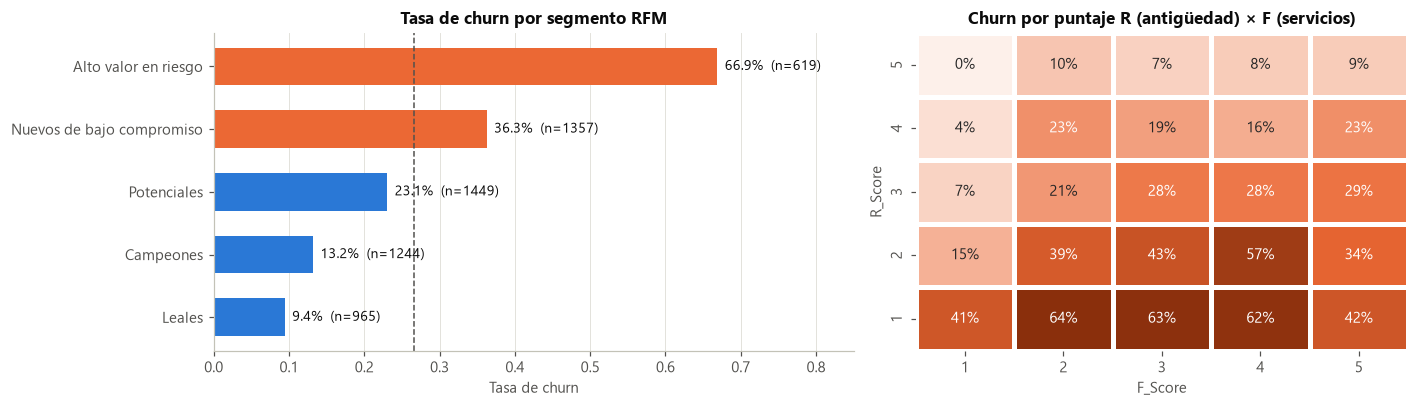

,mean,size
SegmentoRFM,,
Leales,0.094301,965
Campeones,0.131833,1244
Potenciales,0.230504,1449
Nuevos de bajo compromiso,0.362564,1357
Alto valor en riesgo,0.668821,619


In [13]:
# Tasa de churn por segmento RFM y mapa R x F
seg = Xtr_fe.assign(Churn=y_train.values).groupby("SegmentoRFM")["Churn"].agg(["mean", "size"]).sort_values("mean")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.barh(seg.index, seg["mean"], color=[C_SI if m > tasa_global else C_NO for m in seg["mean"]], height=0.6)
for i, (m, n) in enumerate(zip(seg["mean"], seg["size"])):
    ax.text(m + 0.01, i, f"{m:.1%}  (n={n})", va="center", fontsize=9, color=INK)
ax.axvline(tasa_global, color=INK2, ls="--", lw=1); ax.set_xlim(0, 0.85); ax.grid(axis="y", visible=False)
ax.set_title("Tasa de churn por segmento RFM"); ax.set_xlabel("Tasa de churn")
rf_map = Xtr_fe.assign(Churn=y_train.values).pivot_table(index="R_Score", columns="F_Score", values="Churn", aggfunc="mean")
cmap_seq = LinearSegmentedColormap.from_list("seq", ["#fdf0ea", "#eb6834", "#8a2f0c"])
sns.heatmap(rf_map.sort_index(ascending=False), annot=True, fmt=".0%", cmap=cmap_seq, linewidths=2, linecolor="white", ax=axes[1], cbar=False)
axes[1].set_title("Churn por puntaje R (antigüedad) × F (servicios)"); axes[1].set_xlabel("F_Score"); axes[1].set_ylabel("R_Score")
plt.tight_layout(); savefig("05_segmentos_rfm")
seg

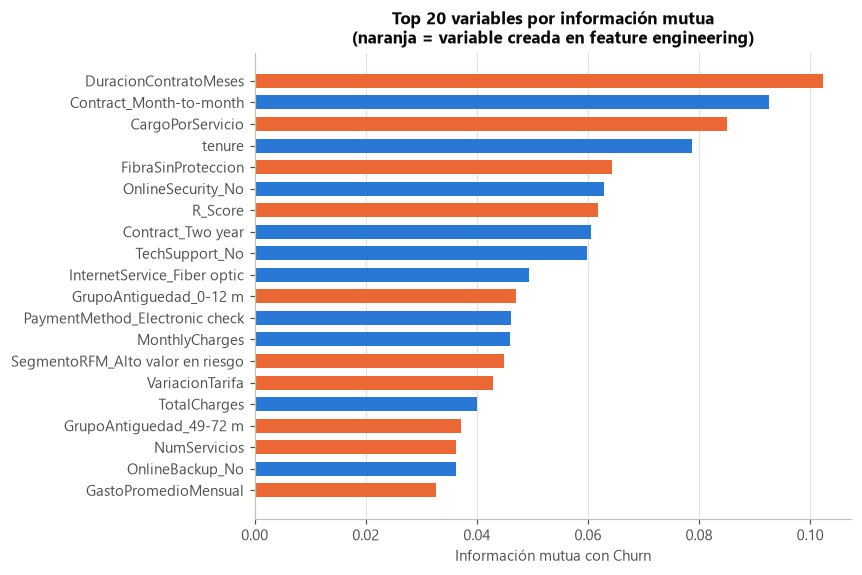

In [14]:
# Información mutua de cada variable con el churn (entrenamiento)
prep_tmp = build_preprocessor().fit(Xtr_fe)
Xtr_mat = prep_tmp.transform(Xtr_fe)
names = prep_tmp.get_feature_names_out()
mi = mutual_info_classif(Xtr_mat, y_train, random_state=SEED,
                         discrete_features=[n.startswith("cat__") for n in names])
mi = pd.Series(mi, index=[n.split("__", 1)[1] for n in names]).sort_values(ascending=False).head(20)
eng = set(ENG_NUMERIC + ENG_CATEGORICAL)
fig, ax = plt.subplots(figsize=(7, 5.5))
cols = [C_SI if any(n == e or n.startswith(e + "_") for e in eng) else C_NO for n in mi.index]
ax.barh(mi.index[::-1], mi.values[::-1], color=cols[::-1], height=0.65)
ax.set_title("Top 20 variables por información mutua\n(naranja = variable creada en feature engineering)")
ax.set_xlabel("Información mutua con Churn"); ax.grid(axis="y", visible=False)
savefig("06_informacion_mutua")

Varias variables derivadas (`DuracionContratoMeses`, `R_Score`, `RFM_Score`, `SegmentoRFM`, `GrupoAntiguedad`, `FibraSinProteccion`, `PagoAutomatico`) aparecen entre las más informativas, lo que confirma el valor del *feature engineering*.

## 3.3 Transformación
- **Numéricas:** estandarización (`StandardScaler`), necesaria para la Regresión Logística y la red neuronal.
- **Categóricas:** *One-Hot Encoding* (`drop='if_binary'` en las variables binarias, `handle_unknown='ignore'`).
- Todo se encapsula en un **`Pipeline`** (`FeatureEngineer → ColumnTransformer → modelo`). Así cada pliegue de la validación cruzada reaprende los cortes RFM y el escalado, sin fuga de información, y en producción basta con entregarle al pipeline los datos crudos.
- **Desbalance (26.5 % churn):** se usa **ajuste del umbral de decisión** sobre predicciones *out-of-fold*, en lugar de sobremuestreo, para conservar probabilidades bien calibradas en el dashboard de riesgo.

In [15]:
print("Dimensión de la matriz final de entrenamiento:", Xtr_mat.shape)

Dimensión de la matriz final de entrenamiento: (5634, 63)


# 4. Modelado
## 4.1 Técnicas seleccionadas
| Modelo | Familia | Justificación |
|---|---|---|
| Regresión Logística | Lineal | Línea base interpretable (odds ratios) |
| Random Forest | Ensamble *bagging* | Reduce varianza promediando árboles descorrelacionados |
| XGBoost | Ensamble *boosting* | Gradiente de segundo orden con regularización L1/L2 |
| LightGBM | Ensamble *boosting* | Crecimiento por hojas (*leaf-wise*), rápido y eficiente |
| Red Neuronal (MLP) | Red neuronal | Captura relaciones no lineales complejas |
| **Stacking** (adicional) | Ensamble apilado | Combina los 5 modelos con un meta-modelo logístico |

## 4.2 Diseño de la prueba
- Partición *hold-out* 80/20 estratificada (el conjunto de prueba no se toca hasta §5).
- Búsqueda aleatoria de hiperparámetros (`RandomizedSearchCV`) con **validación cruzada estratificada de 5 pliegues** y métrica **ROC-AUC**, que no depende del umbral y es robusta al desbalance.

In [16]:
# =====================================================
# DEFINICIÓN DE MODELOS Y ESPACIOS DE BÚSQUEDA
# =====================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(model):
    return Pipeline([("fe", FeatureEngineer()), ("prep", build_preprocessor()), ("model", model)])

modelos = {
    "Regresión Logística": (
        LogisticRegression(max_iter=5000, solver="liblinear", random_state=SEED),
        {"model__C": loguniform(1e-3, 10), "model__penalty": ["l1", "l2"]}, 25),
    "Random Forest": (
        RandomForestClassifier(n_jobs=-1, random_state=SEED),
        {"model__n_estimators": randint(200, 500), "model__max_depth": [6, 8, 10, 12, None],
         "model__min_samples_leaf": randint(3, 20), "model__max_features": ["sqrt", 0.3, 0.5]}, 15),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
        {"model__n_estimators": randint(150, 600), "model__learning_rate": loguniform(0.01, 0.2),
         "model__max_depth": randint(2, 6), "model__subsample": uniform(0.6, 0.4),
         "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 10),
         "model__gamma": uniform(0, 2), "model__reg_lambda": loguniform(0.1, 20)}, 25),
    "LightGBM": (
        LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=-1),
        {"model__n_estimators": randint(150, 600), "model__learning_rate": loguniform(0.01, 0.2),
         "model__num_leaves": randint(4, 32), "model__min_child_samples": randint(10, 80),
         "model__subsample": uniform(0.6, 0.4), "model__subsample_freq": [1],
         "model__colsample_bytree": uniform(0.5, 0.5), "model__reg_lambda": loguniform(0.1, 20)}, 25),
    "Red Neuronal (MLP)": (
        MLPClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.15, random_state=SEED),
        {"model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
         "model__alpha": loguniform(1e-3, 10), "model__learning_rate_init": loguniform(5e-4, 1e-2),
         "model__activation": ["relu", "tanh"]}, 15),
}

In [17]:
# =====================================================
# ENTRENAMIENTO CON BÚSQUEDA DE HIPERPARÁMETROS
# =====================================================
mejores, busqueda = {}, []
for nombre, (est, grid, n_iter) in modelos.items():
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipe(est), grid, n_iter=n_iter, scoring="roc_auc", cv=cv,
                            random_state=SEED, n_jobs=1, refit=True)
    rs.fit(X_train, y_train)
    mejores[nombre] = rs.best_estimator_
    params = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}
    busqueda.append({"modelo": nombre, "roc_auc_cv": rs.best_score_, "std": rs.cv_results_["std_test_score"][rs.best_index_],
                     "segundos": time.time() - t0, "mejores_hiperparametros": params})
    print(f"{nombre:22s} ROC-AUC CV = {rs.best_score_:.4f}  ({time.time() - t0:.0f}s)  {params}")

Regresión Logística    ROC-AUC CV = 0.8463  (108s)  {'C': np.float64(0.1256), 'penalty': 'l1'}


Random Forest          ROC-AUC CV = 0.8472  (271s)  {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 19, 'n_estimators': 258}


XGBoost                ROC-AUC CV = 0.8497  (373s)  {'colsample_bytree': np.float64(0.5697), 'gamma': np.float64(1.2088), 'learning_rate': np.float64(0.0504), 'max_depth': 2, 'min_child_weight': 4, 'n_estimators': 162, 'reg_lambda': np.float64(0.1504), 'subsample': np.float64(0.7159)}


LightGBM               ROC-AUC CV = 0.8487  (310s)  {'colsample_bytree': np.float64(0.6374), 'learning_rate': np.float64(0.0537), 'min_child_samples': 56, 'n_estimators': 280, 'num_leaves': 4, 'reg_lambda': np.float64(4.5785), 'subsample': np.float64(0.6944), 'subsample_freq': 1}


Red Neuronal (MLP)     ROC-AUC CV = 0.8446  (160s)  {'activation': 'tanh', 'alpha': np.float64(0.0292), 'hidden_layer_sizes': (64,), 'learning_rate_init': np.float64(0.0016)}


In [18]:
# =====================================================
# STACKING (ENSAMBLE APILADO) CON LOS 5 MODELOS AJUSTADOS
# =====================================================
t0 = time.time()
stack = StackingClassifier(
    estimators=[(n.split(" ")[0].lower(), p) for n, p in mejores.items()],
    final_estimator=LogisticRegression(max_iter=2000), cv=cv, stack_method="predict_proba", n_jobs=1)
stack.fit(X_train, y_train)
mejores["Stacking"] = stack
print(f"Stacking entrenado en {time.time() - t0:.0f}s")

Stacking entrenado en 54s


In [19]:
# =====================================================
# VALIDACIÓN CRUZADA CON VARIAS MÉTRICAS + PREDICCIONES OUT-OF-FOLD
# (las predicciones OOF se usan para elegir el umbral sin mirar el test)
# =====================================================
cv_rows, oof = [], {}
for nombre, modelo in mejores.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=1)
    for k in range(5):
        cv_rows.append({"modelo": nombre, "fold": k, "Accuracy": r["test_accuracy"][k],
                        "F1": r["test_f1"][k], "ROC-AUC": r["test_roc_auc"][k]})
    oof[nombre] = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(REP / "validacion_cruzada.csv", index=False)
resumen_cv = cv_df.groupby("modelo")[["Accuracy", "F1", "ROC-AUC"]].agg(["mean", "std"]).round(4)
resumen_cv.sort_values(("ROC-AUC", "mean"), ascending=False)

Accuracy              F1         ROC-AUC        
                        mean     std    mean     std    mean     std
modelo                                                              
Stacking              0.8037  0.0164  0.5821  0.0324  0.8500  0.0127
XGBoost               0.8040  0.0118  0.5845  0.0268  0.8497  0.0145
LightGBM              0.8033  0.0154  0.5880  0.0366  0.8487  0.0138
Random Forest         0.8028  0.0144  0.5743  0.0256  0.8472  0.0120
Regresión Logística   0.8048  0.0118  0.5840  0.0271  0.8463  0.0120
Red Neuronal (MLP)    0.8014  0.0059  0.5773  0.0211  0.8446  0.0125

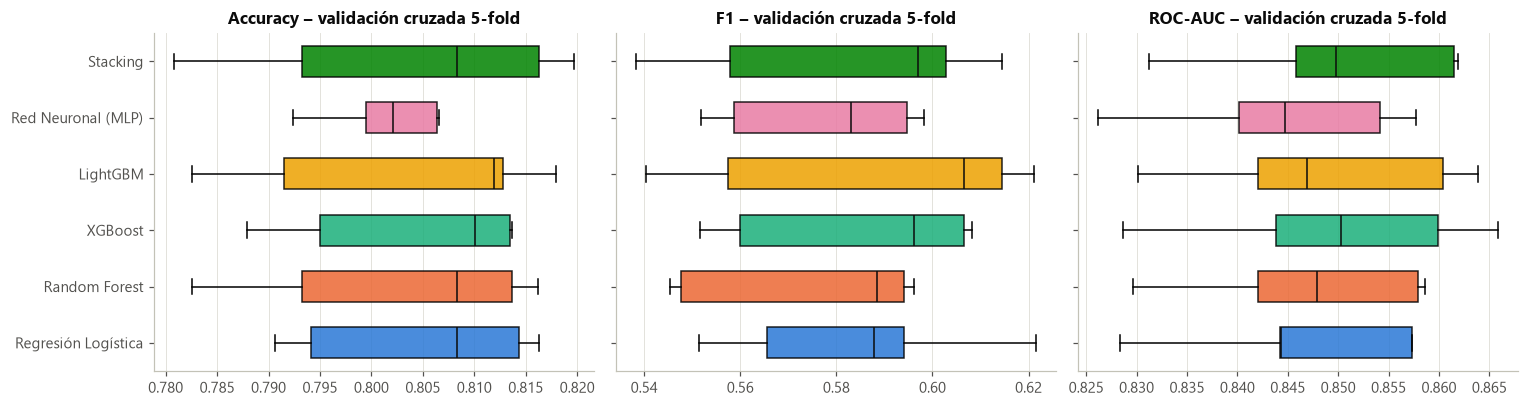

In [20]:
orden = list(mejores.keys())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, met in zip(axes, ["Accuracy", "F1", "ROC-AUC"]):
    data = [cv_df.loc[cv_df.modelo == m, met] for m in orden]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.55, medianprops={"color": INK})
    for patch, c in zip(bp["boxes"], MODEL_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.85)
    ax.set_yticks(range(1, len(orden) + 1), orden); ax.set_title(f"{met} – validación cruzada 5-fold")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("07_validacion_cruzada")

Con el umbral por defecto (0.5) el F1 de la clase churn es moderado, porque la clase minoritaria representa solo el 26.5 %. Por eso, en la evaluación se optimiza el umbral de decisión con las predicciones *out-of-fold* de entrenamiento.

# 5. Evaluación
## 5.1 Selección del umbral de decisión
Para cada modelo se elige el umbral que **maximiza F1** sobre las predicciones *out-of-fold* de entrenamiento. El conjunto de prueba nunca se usa para tomar decisiones.

In [21]:
def best_threshold(y_true, prob):
    grid = np.arange(0.10, 0.71, 0.01)
    f1s = [f1_score(y_true, (prob >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])

umbrales = {m: best_threshold(y_train, oof[m]) for m in mejores}
pd.Series(umbrales, name="umbral óptimo F1 (OOF)")

Regresión Logística    0.33
Random Forest          0.37
XGBoost                0.30
LightGBM               0.28
Red Neuronal (MLP)     0.34
Stacking               0.27
Name: umbral óptimo F1 (OOF), dtype: float64

## 5.2 Métricas en el conjunto de prueba (datos nunca vistos)

In [22]:
# =====================================================
# EVALUACIÓN EN TEST
# =====================================================
def metricas(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob),
            "Brier": brier_score_loss(y_true, prob)}

prob_test = {m: mod.predict_proba(X_test)[:, 1] for m, mod in mejores.items()}
filas = []
for m in mejores:
    filas.append({"modelo": m, "umbral": 0.5, **metricas(y_test, prob_test[m], 0.5)})
    filas.append({"modelo": m, "umbral": umbrales[m], **metricas(y_test, prob_test[m], umbrales[m])})
res = pd.DataFrame(filas)
res["roc_auc_cv"] = res["modelo"].map(cv_df.groupby("modelo")["ROC-AUC"].mean())
res.to_csv(REP / "metricas_modelos.csv", index=False)
tabla_opt = res[res.umbral != 0.5].set_index("modelo").sort_values("ROC-AUC", ascending=False)
print("=== Con umbral 0.5 ===")
display(res[res.umbral == 0.5].set_index("modelo").drop(columns="umbral").round(4))
print("=== Con umbral óptimo (OOF) ===")
tabla_opt.round(4)

=== Con umbral 0.5 ===


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,roc_auc_cv
modelo,,,,,,,,
Regresión Logística,0.8027,0.6690,0.5080,0.5775,0.8457,0.6456,0.1362,0.8463
Random Forest,0.8006,0.6679,0.4947,0.5684,0.8454,0.6544,0.1357,0.8472
XGBoost,0.8027,0.6633,0.5214,0.5838,0.8466,0.6643,0.1349,0.8497
LightGBM,0.8105,0.6826,0.5348,0.5997,0.8483,0.6636,0.1347,0.8487
Red Neuronal (MLP),0.7857,0.6059,0.5508,0.5770,0.8336,0.6226,0.1443,0.8446
Stacking,0.8041,0.6713,0.5134,0.5818,0.8480,0.6587,0.1362,0.8500


=== Con umbral óptimo (OOF) ===


,umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,roc_auc_cv
modelo,,,,,,,,,
LightGBM,0.28,0.7559,0.5271,0.7807,0.6293,0.8483,0.6636,0.1347,0.8487
Stacking,0.27,0.7736,0.5556,0.7353,0.6329,0.8480,0.6587,0.1362,0.8500
XGBoost,0.30,0.7622,0.5360,0.7754,0.6339,0.8466,0.6643,0.1349,0.8497
Regresión Logística,0.33,0.7686,0.5486,0.7246,0.6244,0.8457,0.6456,0.1362,0.8463
Random Forest,0.37,0.7793,0.5705,0.6818,0.6212,0.8454,0.6544,0.1357,0.8472
Red Neuronal (MLP),0.34,0.7700,0.5517,0.7139,0.6224,0.8336,0.6226,0.1443,0.8446


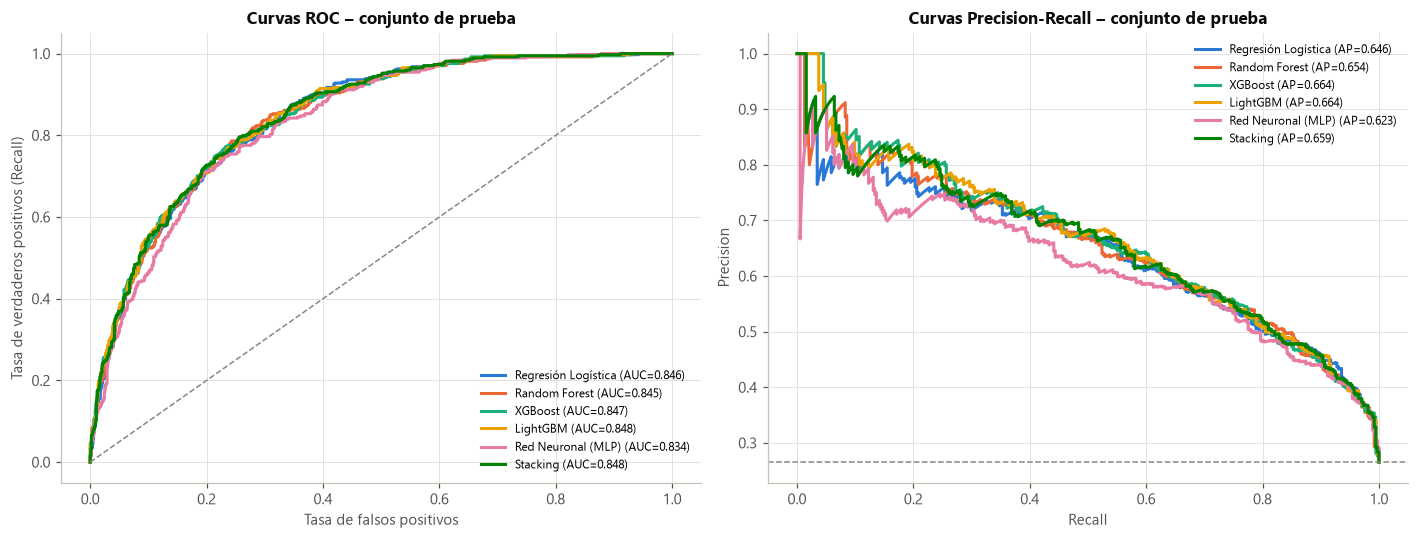

In [23]:
# =====================================================
# CURVAS ROC Y PRECISION-RECALL
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (m, p), c in zip(prob_test.items(), MODEL_COLORS):
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{m} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=c, lw=2, label=f"{m} (AP={average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#898781", lw=1)
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (Recall)", title="Curvas ROC – conjunto de prueba")
axes[1].axhline(y_test.mean(), ls="--", color="#898781", lw=1)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Curvas Precision-Recall – conjunto de prueba")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); savefig("08_curvas_roc_pr")

# Guardar puntos de las curvas ROC para la app web
curvas = {}
for m, p in prob_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    idx = np.linspace(0, len(fpr) - 1, 120).astype(int)
    curvas[m] = {"fpr": fpr[idx].round(4).tolist(), "tpr": tpr[idx].round(4).tolist()}
json.dump(curvas, open(REP / "curvas_roc.json", "w"))

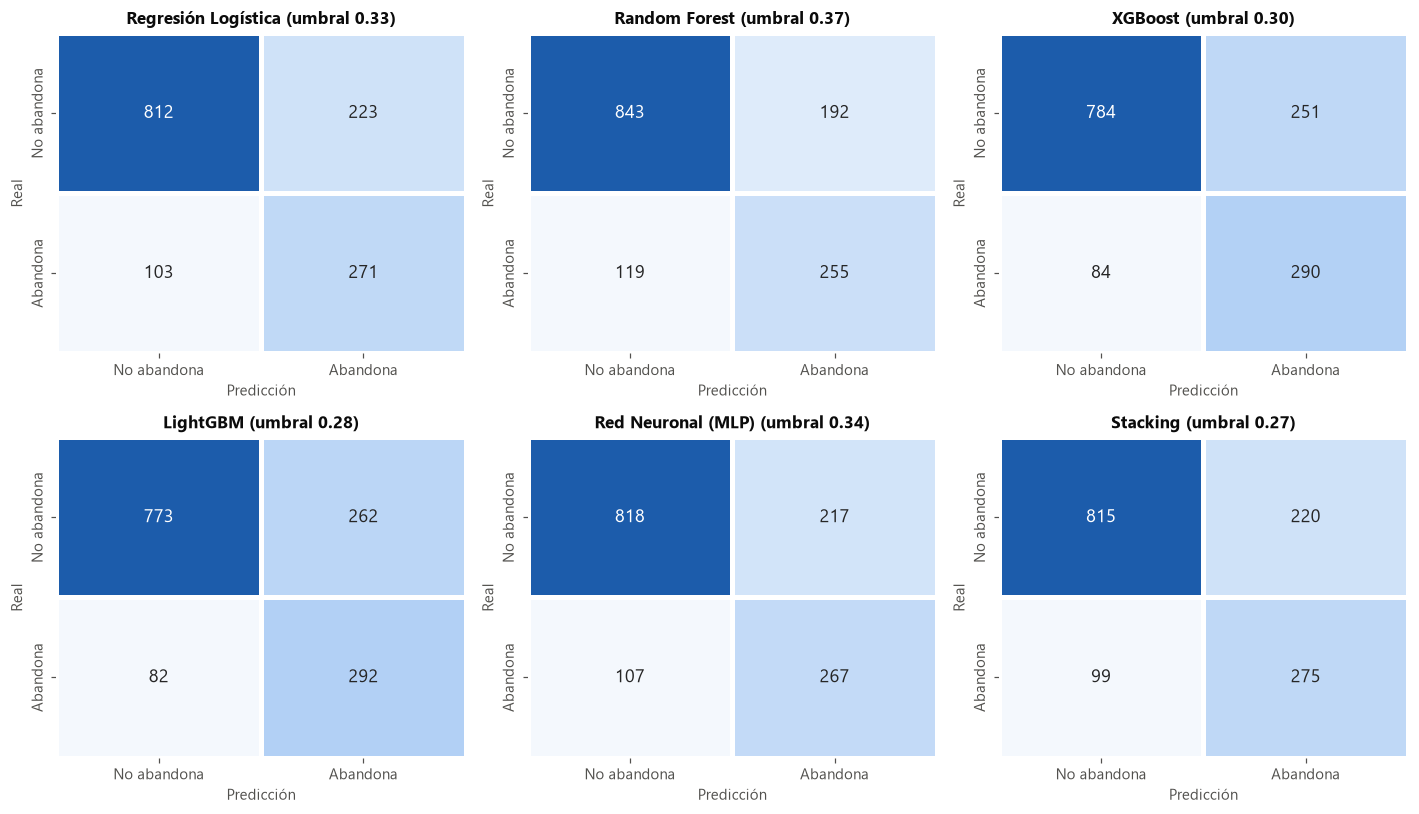

In [24]:
# =====================================================
# MATRICES DE CONFUSIÓN (umbral óptimo)
# =====================================================
cmap_cm = LinearSegmentedColormap.from_list("cm", ["#f4f8fd", "#86b6ef", "#1c5cab"])
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
mats = {}
for ax, m in zip(axes.ravel(), mejores):
    cm = confusion_matrix(y_test, (prob_test[m] >= umbrales[m]).astype(int)); mats[m] = cm.tolist()
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap_cm, cbar=False, ax=ax, linewidths=2, linecolor="white",
                xticklabels=["No abandona", "Abandona"], yticklabels=["No abandona", "Abandona"], annot_kws={"size": 12})
    ax.set_title(f"{m} (umbral {umbrales[m]:.2f})"); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); savefig("09_matrices_confusion")
json.dump(mats, open(REP / "matrices_confusion.json", "w"))

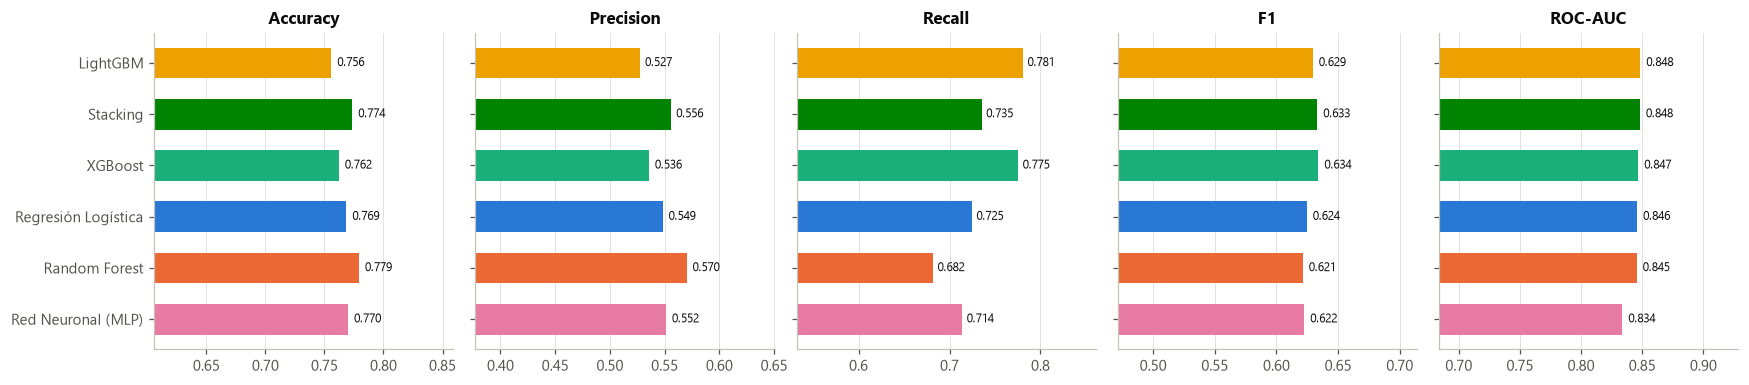

In [25]:
# Comparación visual de métricas en test (umbral óptimo)
mets = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, axes = plt.subplots(1, len(mets), figsize=(16, 3.6), sharey=True)
orden_m = tabla_opt.index.tolist()[::-1]
for ax, met in zip(axes, mets):
    vals = tabla_opt.loc[orden_m, met]
    ax.barh(orden_m, vals, color=[MODEL_COLORS[orden.index(m)] for m in orden_m], height=0.6)
    for i, v in enumerate(vals): ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
    ax.set_xlim(max(0, vals.min() - 0.15), min(1, vals.max() + 0.08)); ax.set_title(met); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("10_comparacion_metricas")

## 5.3 Selección del modelo final
**Regla de selección (definida antes de ver el test):**
1. Mayor ROC-AUC promedio en validación cruzada (`roc_auc_cv`).
2. Si la diferencia con el mejor es < 0.003 (dentro del ruido estadístico entre pliegues), se prefiere el modelo **más simple de explicar con SHAP exacto** (árboles con TreeSHAP o el lineal), por parsimonia y velocidad de inferencia en la aplicación.

In [26]:
# =====================================================
# SELECCIÓN DEL MODELO FINAL
# =====================================================
auc_cv = cv_df.groupby("modelo")["ROC-AUC"].mean().sort_values(ascending=False)
explicables = ["XGBoost", "LightGBM", "Random Forest", "Regresión Logística"]
mejor_auc = auc_cv.iloc[0]
candidatos = [m for m in auc_cv.index if m in explicables and mejor_auc - auc_cv[m] < 0.003]
FINAL = candidatos[0] if candidatos else auc_cv.index[0]
modelo_final = mejores[FINAL]
THR = umbrales[FINAL]
print(auc_cv.round(4))
print(f"\n>>> Modelo final: {FINAL} | umbral de decisión = {THR:.2f}")
print(classification_report(y_test, (prob_test[FINAL] >= THR).astype(int), target_names=["No abandona", "Abandona"]))

modelo
Stacking               0.8500
XGBoost                0.8497
LightGBM               0.8487
Random Forest          0.8472
Regresión Logística    0.8463
Red Neuronal (MLP)     0.8446
Name: ROC-AUC, dtype: float64

>>> Modelo final: XGBoost | umbral de decisión = 0.30
              precision    recall  f1-score   support

 No abandona       0.90      0.76      0.82      1035
    Abandona       0.54      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [27]:
# Intervalo de confianza 95% del ROC-AUC en test (bootstrap, 1000 réplicas)
rng = np.random.default_rng(SEED); yt = y_test.values; pf = prob_test[FINAL]
boots = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() != yt[i].max(): boots.append(roc_auc_score(yt[i], pf[i]))
ic = np.percentile(boots, [2.5, 97.5])
print(f"ROC-AUC {FINAL} en test = {roc_auc_score(yt, pf):.4f}  IC95% [{ic[0]:.4f}, {ic[1]:.4f}]")

ROC-AUC XGBoost en test = 0.8466  IC95% [0.8243, 0.8672]


## 5.4 Evaluación orientada al negocio: curva de ganancia acumulada (*lift*)
Si el equipo de retención solo puede contactar a una parte de los clientes, ¿qué proporción de los que realmente abandonan logra capturar ordenándolos por riesgo?

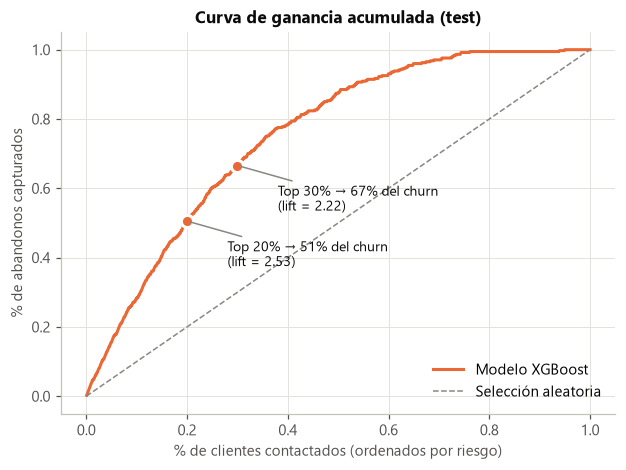

Contactando al 30% de mayor riesgo se captura el 66.6% de los abandonos (lift 2.22)


In [28]:
orden_idx = np.argsort(-pf); y_ord = yt[orden_idx]
frac = np.arange(1, len(yt) + 1) / len(yt); captura = np.cumsum(y_ord) / y_ord.sum()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(frac, captura, color=C_SI, lw=2, label=f"Modelo {FINAL}")
ax.plot([0, 1], [0, 1], ls="--", color="#898781", lw=1, label="Selección aleatoria")
for f in (0.2, 0.3):
    c = captura[int(f * len(yt)) - 1]
    ax.plot(f, c, "o", color=C_SI, ms=8, mec="white", mew=2)
    ax.annotate(f"Top {f:.0%} → {c:.0%} del churn\n(lift = {c / f:.2f})", (f, c), xytext=(f + 0.08, c - 0.13),
                fontsize=9, color=INK, arrowprops={"arrowstyle": "-", "color": "#898781"})
ax.set(xlabel="% de clientes contactados (ordenados por riesgo)", ylabel="% de abandonos capturados",
       title="Curva de ganancia acumulada (test)"); ax.legend(loc="lower right")
savefig("11_curva_ganancia")
captura_30 = captura[int(0.3 * len(yt)) - 1]
print(f"Contactando al 30% de mayor riesgo se captura el {captura_30:.1%} de los abandonos (lift {captura_30 / 0.3:.2f})")

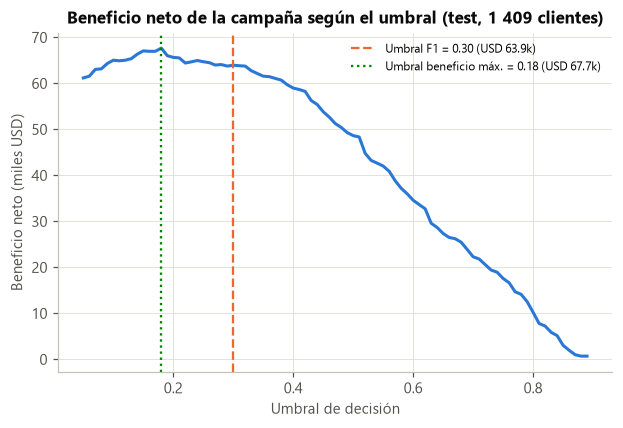

In [29]:
# =====================================================
# ANÁLISIS COSTO-BENEFICIO DEL UMBRAL
# Supuestos: costo contacto+incentivo = USD 50, éxito retención = 35%,
# valor recuperado = 12 meses del cargo mensual del cliente.
# =====================================================
COSTO, EXITO = 50, 0.35
valor_anual = X_test["MonthlyCharges"].values * 12
def beneficio(thr):
    sel = pf >= thr
    return (yt[sel] * valor_anual[sel] * EXITO).sum() - COSTO * sel.sum()
grid = np.arange(0.05, 0.9, 0.01); ben = np.array([beneficio(t) for t in grid])
thr_negocio = float(grid[ben.argmax()])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(grid, ben / 1000, color=C_NO, lw=2)
ax.axvline(THR, color=C_SI, ls="--", lw=1.5, label=f"Umbral F1 = {THR:.2f} (USD {beneficio(THR) / 1000:,.1f}k)")
ax.axvline(thr_negocio, color="#008300", ls=":", lw=1.5, label=f"Umbral beneficio máx. = {thr_negocio:.2f} (USD {ben.max() / 1000:,.1f}k)")
ax.set(xlabel="Umbral de decisión", ylabel="Beneficio neto (miles USD)", title="Beneficio neto de la campaña según el umbral (test, 1 409 clientes)")
ax.legend(fontsize=8); savefig("12_costo_beneficio")

## 5.5 Interpretabilidad con SHAP
SHAP (*SHapley Additive exPlanations*) asigna a cada variable su contribución a la predicción de cada cliente, con base en la teoría de juegos (valores de Shapley). Para modelos de árboles se usa **TreeSHAP**, que calcula los valores exactos de forma eficiente. Las contribuciones de las columnas *one-hot* se **suman** para expresarlas por variable original.

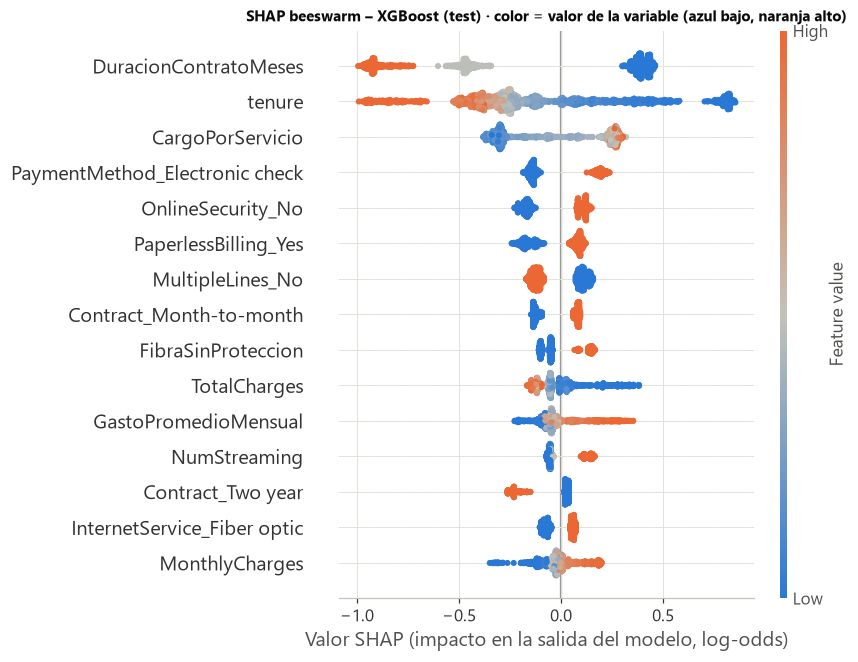

In [30]:
# =====================================================
# SHAP – EXPLICACIÓN GLOBAL
# =====================================================
prep_f = modelo_final[:-1]                      # FeatureEngineer + ColumnTransformer
est_f = modelo_final.named_steps["model"]
Xte_mat = prep_f.transform(X_test)
tnames = prep_f.get_feature_names_out()

def make_explainer(est, background):
    if isinstance(est, LogisticRegression):
        return shap.LinearExplainer(est, background)
    return shap.TreeExplainer(est)

def shap_matrix(explainer, M):
    sv = explainer.shap_values(M)
    if isinstance(sv, list): sv = sv[1]
    if sv.ndim == 3: sv = sv[:, :, 1]
    return sv

explainer = make_explainer(est_f, prep_f.transform(X_train))
# Random Forest explica en probabilidad; boosting y regresión logística en log-odds
SHAP_UNIT = "probabilidad" if isinstance(est_f, RandomForestClassifier) else "log-odds"
fmt = lambda v: f"{v:.2f}" if isinstance(v, (float, np.floating)) and not float(v).is_integer() else (int(v) if isinstance(v, (float, np.floating)) else v)
sv_test = shap_matrix(explainer, Xte_mat)
pretty = [n.split("__", 1)[1] for n in tnames]

cmap_feat = LinearSegmentedColormap.from_list("feat", ["#2a78d6", "#c3c2b7", "#eb6834"])
plt.figure()
shap.summary_plot(sv_test, Xte_mat, feature_names=pretty, max_display=15, cmap=cmap_feat, show=False, plot_size=(8, 6))
plt.gca().set_xlabel(f"Valor SHAP (impacto en la salida del modelo, {SHAP_UNIT})")
plt.title(f"SHAP beeswarm – {FINAL} (test) · color = valor de la variable (azul bajo, naranja alto)", fontsize=10)
savefig("13_shap_beeswarm")

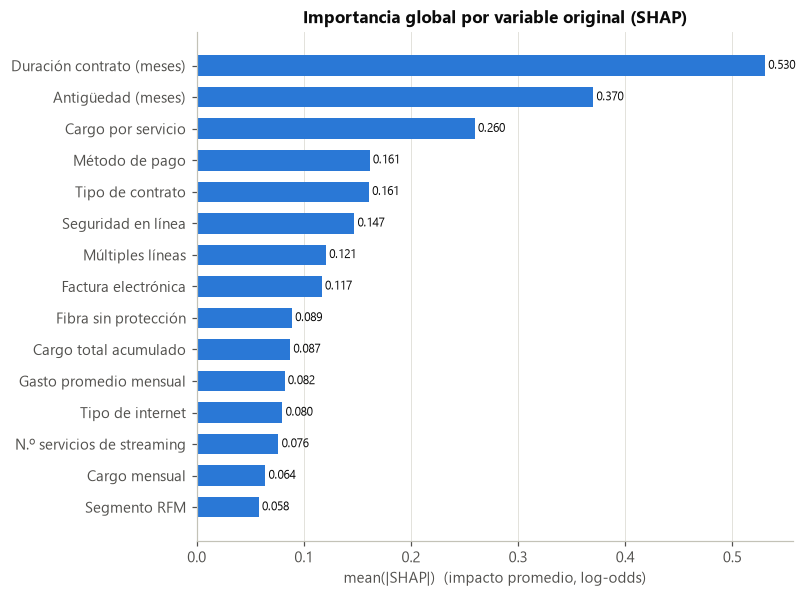

Duración contrato (meses)    0.530477
Antigüedad (meses)           0.370090
Cargo por servicio           0.259511
Método de pago               0.161446
Tipo de contrato             0.160740
Seguridad en línea           0.147100
Múltiples líneas             0.120655
Factura electrónica          0.116718
Fibra sin protección         0.088906
Cargo total acumulado        0.087209
dtype: float32

In [31]:
# Importancia global agregada por variable original
agg = aggregate_shap(sv_test, tnames)
imp = agg.abs().mean().sort_values(ascending=False)
imp.index = [FEATURE_LABELS.get(c, c) for c in imp.index]
fig, ax = plt.subplots(figsize=(7, 6))
top = imp.head(15)[::-1]
ax.barh(top.index, top.values, color=C_NO, height=0.65)
for i, v in enumerate(top.values): ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set(xlabel=f"mean(|SHAP|)  (impacto promedio, {SHAP_UNIT})", title="Importancia global por variable original (SHAP)")
ax.grid(axis="y", visible=False); savefig("14_shap_importancia_global")
imp.round(4).to_frame("mean_abs_shap").to_csv(REP / "shap_importancia_global.csv")
imp.head(10)

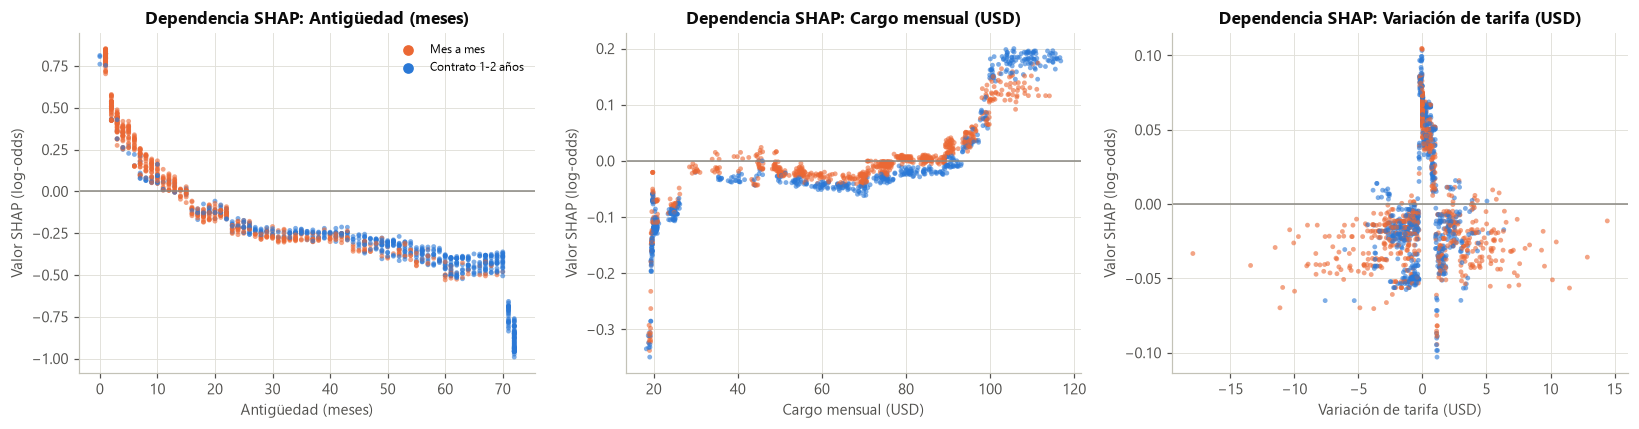

In [32]:
# Gráficos de dependencia: cómo cambia el efecto con el valor de la variable
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (feat, label) in zip(axes, [("num__tenure", "Antigüedad (meses)"), ("num__MonthlyCharges", "Cargo mensual (USD)"),
                                    ("num__VariacionTarifa", "Variación de tarifa (USD)")]):
    j = list(tnames).index(feat); raw_col = feat.split("__")[1]
    xs = prep_f.named_steps["fe"].transform(X_test)[raw_col].values
    ax.scatter(xs, sv_test[:, j], s=10, alpha=0.6, c=np.where(X_test["Contract"].values == "Month-to-month", C_SI, C_NO), edgecolors="none")
    ax.axhline(0, color="#898781", lw=1); ax.set(xlabel=label, ylabel=f"Valor SHAP ({SHAP_UNIT})", title=f"Dependencia SHAP: {label}")
axes[0].scatter([], [], c=C_SI, label="Mes a mes"); axes[0].scatter([], [], c=C_NO, label="Contrato 1-2 años"); axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("15_shap_dependencia")

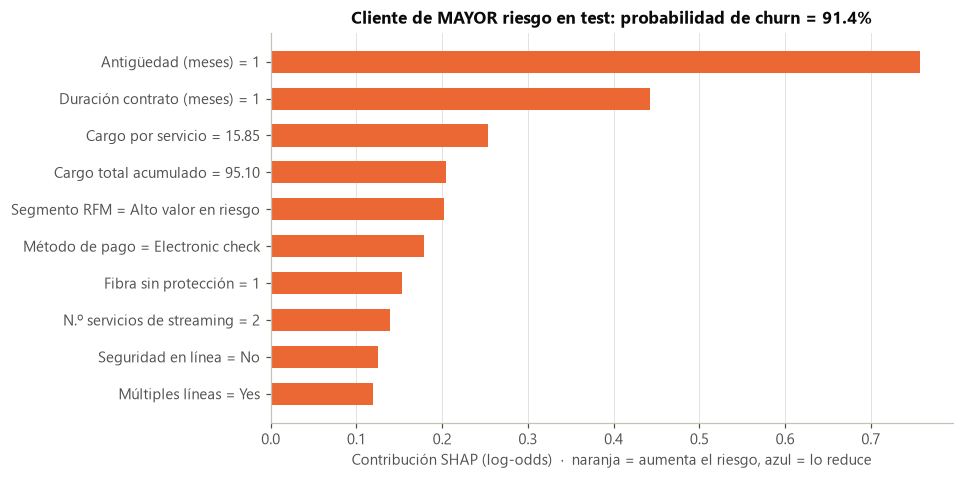

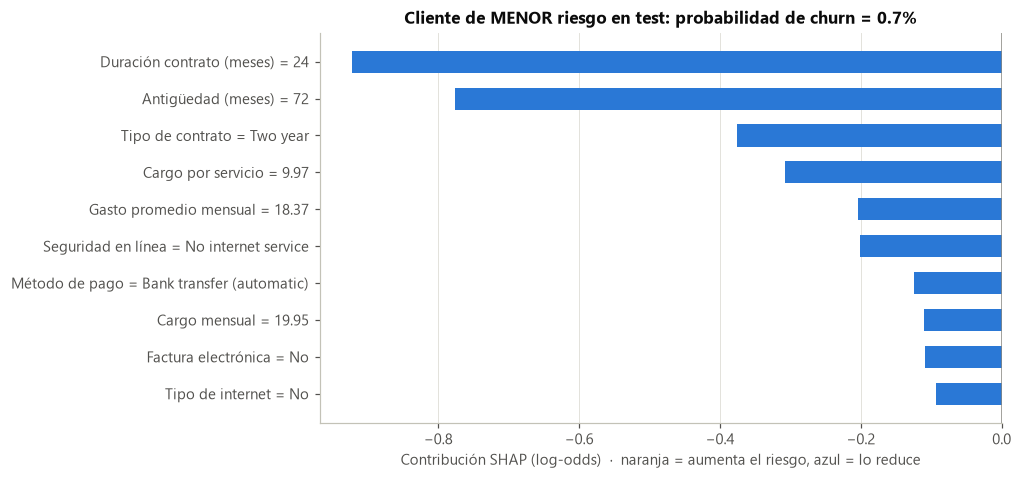

In [33]:
# =====================================================
# SHAP – EXPLICACIÓN LOCAL (cliente individual)
# =====================================================
base = float(np.ravel(explainer.expected_value)[-1])
def plot_local(i, nombre):
    contrib = agg.iloc[i].sort_values(key=np.abs, ascending=False).head(10)[::-1]
    raw = X_test.iloc[i]
    fe_row = prep_f.named_steps["fe"].transform(X_test.iloc[[i]]).iloc[0]
    labels = [f"{FEATURE_LABELS.get(c, c)} = {fmt(fe_row[c] if c in fe_row else raw.get(c))}" for c in contrib.index]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(labels, contrib.values, color=[C_SI if v > 0 else C_NO for v in contrib.values], height=0.6)
    ax.axvline(0, color="#898781", lw=1); ax.grid(axis="y", visible=False)
    ax.set(xlabel=f"Contribución SHAP ({SHAP_UNIT})  ·  naranja = aumenta el riesgo, azul = lo reduce",
           title=f"{nombre}: probabilidad de churn = {pf[i]:.1%}")
    savefig(f"16_shap_local_{'alto' if pf[i] > 0.5 else 'bajo'}")
plot_local(int(np.argmax(pf)), "Cliente de MAYOR riesgo en test")
plot_local(int(np.argmin(pf)), "Cliente de MENOR riesgo en test")

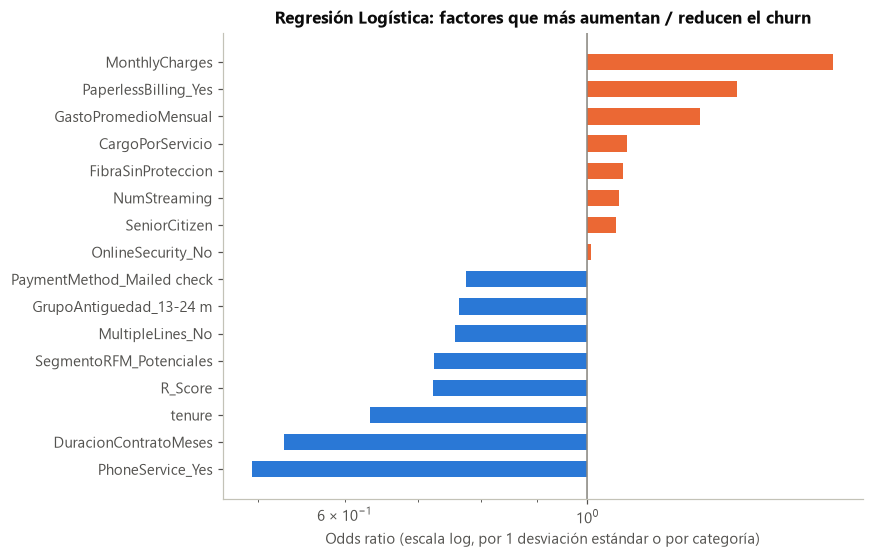

In [34]:
# Interpretación complementaria: odds ratios de la Regresión Logística
lr = mejores["Regresión Logística"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=[n.split("__", 1)[1] for n in lr[:-1].get_feature_names_out()])
coef = coef[coef != 0]
odds = np.exp(coef).sort_values()
sel = pd.concat([odds.head(8), odds.tail(8)])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(sel.index, sel.values - 1, left=1, color=[C_SI if v > 1 else C_NO for v in sel.values], height=0.6)
ax.axvline(1, color="#898781", lw=1); ax.set_xscale("log"); ax.grid(axis="y", visible=False)
ax.set(xlabel="Odds ratio (escala log, por 1 desviación estándar o por categoría)", title="Regresión Logística: factores que más aumentan / reducen el churn")
savefig("17_odds_ratios_lr")

**Interpretación de SHAP (explicabilidad)**
- El **tipo de contrato** es el factor dominante: el contrato mes a mes eleva fuertemente el riesgo y los contratos de 1 o 2 años lo reducen.
- La **antigüedad** tiene un efecto no lineal: el riesgo es muy alto en los primeros meses y cae de forma pronunciada después del primer año.
- **Fibra óptica**, **cargos mensuales altos**, **ausencia de seguridad en línea y soporte técnico** y **pago con cheque electrónico** aumentan el riesgo.
- Las variables RFM y derivadas (`DuracionContratoMeses`, `NumProteccion`, `FibraSinProteccion`, `PagoAutomatico`) aportan señal complementaria.
- Estos factores son **accionables**: cada uno se traduce en una regla de retención (ver `src/features.py → recommend()`), y las reglas se ordenan por el SHAP individual de cada cliente.

In [35]:
# =====================================================
# VERIFICACIÓN DE CRITERIOS DE ÉXITO
# =====================================================
m_final = tabla_opt.loc[FINAL]
criterios = pd.DataFrame([
    {"criterio": "ROC-AUC test ≥ 0.84", "valor": round(m_final["ROC-AUC"], 4), "cumple": m_final["ROC-AUC"] >= 0.84},
    {"criterio": "Recall churn ≥ 0.70", "valor": round(m_final["Recall"], 4), "cumple": m_final["Recall"] >= 0.70},
    {"criterio": "Top 30% captura ≥ 60% del churn", "valor": round(captura_30, 4), "cumple": captura_30 >= 0.60},
])
criterios

,criterio,valor,cumple
0,ROC-AUC test ≥ 0.84,0.8466,True
1,Recall churn ≥ 0.70,0.7754,True
2,Top 30% captura ≥ 60% del churn,0.6658,True


# 6. Despliegue
Se guardan los artefactos que consume la aplicación web (`app/Inicio.py`, en Streamlit):
- `models/modelo_final.joblib`: pipeline completo (datos crudos → probabilidad).
- `models/<modelo>.joblib`: los 6 modelos, para compararlos en la app.
- `models/metadata.json`: modelo elegido, umbrales, métricas y versiones.
- `data/clientes_scored.csv`: puntuación de toda la cartera con probabilidad, nivel de riesgo, segmento riesgo × valor, principales factores SHAP y recomendaciones (alimenta el dashboard).

In [36]:
# =====================================================
# GUARDAR MODELOS
# =====================================================
slug = {"Regresión Logística": "regresion_logistica", "Random Forest": "random_forest", "XGBoost": "xgboost",
        "LightGBM": "lightgbm", "Red Neuronal (MLP)": "mlp", "Stacking": "stacking"}
for m, mod in mejores.items():
    joblib.dump(mod, MODELS / f"{slug[m]}.joblib", compress=3)
joblib.dump(modelo_final, MODELS / "modelo_final.joblib", compress=3)
for f in sorted(MODELS.glob("*.joblib")): print(f"{f.name:28s} {f.stat().st_size / 1e6:6.2f} MB")

lightgbm.joblib                0.06 MB
mlp.joblib                     0.10 MB
modelo_final.joblib            0.03 MB
random_forest.joblib           1.55 MB
regresion_logistica.joblib     0.00 MB
stacking.joblib                3.47 MB
xgboost.joblib                 0.03 MB


In [37]:
# =====================================================
# PUNTUAR TODA LA CARTERA (para el dashboard)
# =====================================================
HIGH = 0.60
prob_all = modelo_final.predict_proba(X)[:, 1]
sv_all = shap_matrix(explainer, prep_f.transform(X))
agg_all = aggregate_shap(sv_all, tnames)
fe_all = prep_f.named_steps["fe"].transform(X)
valor_anual_all = X["MonthlyCharges"].values * 12
VALUE_CUT = float(np.median(valor_anual_all))

drivers, recs_txt = [], []
for i in range(len(X)):
    s = agg_all.iloc[i]
    top = s[s > 0].sort_values(ascending=False).head(3)
    drivers.append(" | ".join(FEATURE_LABELS.get(c, c) for c in top.index))
    row = {**X.iloc[i].to_dict(), **fe_all.iloc[i].to_dict()}
    recs_txt.append(" | ".join(r["accion"] for r in recommend(row, s.to_dict())))

scored = df[[ID_COL] + RAW_FEATURES].copy()
scored["ChurnReal"] = df[TARGET].values
scored["Conjunto"] = np.where(scored.index.isin(X_test.index), "test", "train")
scored["ProbChurn"] = prob_all.round(4)
scored["NivelRiesgo"] = [risk_level(p, THR, HIGH) for p in prob_all]
scored["ValorAnual"] = valor_anual_all.round(2)
scored["PerdidaEsperada"] = (prob_all * valor_anual_all).round(2)
scored["Prioridad"] = [value_segment(p, v, THR, VALUE_CUT) for p, v in zip(prob_all, valor_anual_all)]
scored["SegmentoRFM"] = fe_all["SegmentoRFM"].values
scored["RFM_Score"] = fe_all["RFM_Score"].values
scored["FactoresRiesgo"] = drivers
scored["Recomendaciones"] = recs_txt
scored.to_csv(DATA / "clientes_scored.csv", index=False)
print(scored["NivelRiesgo"].value_counts())
scored.sort_values("ProbChurn", ascending=False).head(10)[[ID_COL, "ProbChurn", "NivelRiesgo", "Prioridad", "FactoresRiesgo", "Recomendaciones"]]

NivelRiesgo
Bajo     4379
Medio    1707
Alto      957
Name: count, dtype: int64


,customerID,ProbChurn,NivelRiesgo,Prioridad,FactoresRiesgo,Recomendaciones
2208,7216-EWTRS,0.9204,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
3380,5178-LMXOP,0.9144,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
4800,9300-AGZNL,0.9100,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
1976,9497-QCMMS,0.9086,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
6482,5419-JPRRN,0.9071,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
6866,0295-PPHDO,0.9016,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
2577,4910-GMJOT,0.9001,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
3209,8149-RSOUN,0.8961,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
1704,0107-YHINA,0.8951,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...
6240,6521-YYTYI,0.8887,Alto,"1. Retener ya (alto riesgo, alto valor)",Antigüedad (meses) | Duración contrato (meses)...,Programa de bienvenida (onboarding) | Incentiv...


In [38]:
# =====================================================
# METADATA DEL MODELO
# =====================================================
metadata = {
    "proyecto": "Churn Prediction Inteligente – Grupo 6",
    "integrantes": ["Luis Mario Chamizo Tiafi", "Juan Diego Chamizo Tiafi"],
    "fecha_entrenamiento": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "modelo_final": FINAL, "archivo_modelo_final": "modelo_final.joblib",
    "archivos_modelos": {m: f"{slug[m]}.joblib" for m in mejores},
    "umbral_decision": round(THR, 2), "umbral_riesgo_alto": HIGH,
    "umbral_beneficio_maximo": round(thr_negocio, 2), "corte_valor_alto": round(VALUE_CUT, 2),
    "umbrales_por_modelo": {m: round(t, 2) for m, t in umbrales.items()},
    "metricas_test": {m: {k: round(float(v), 4) for k, v in tabla_opt.loc[m].items() if k != "umbral"} for m in tabla_opt.index},
    "auc_ic95_final": [round(ic[0], 4), round(ic[1], 4)],
    "captura_top30": round(float(captura_30), 4),
    "busqueda_hiperparametros": [{**b, "roc_auc_cv": round(b["roc_auc_cv"], 4), "std": round(b["std"], 4), "segundos": round(b["segundos"], 1)} for b in busqueda],
    "tasa_churn_base": round(float(y.mean()), 4), "n_train": len(X_train), "n_test": len(X_test),
    "shap_base_value": base, "shap_unidad": SHAP_UNIT,
    "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                  "lightgbm": lightgbm.__version__, "shap": shap.__version__, "pandas": pd.__version__},
}
json.dump(metadata, open(MODELS / "metadata.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: metadata[k] for k in ["modelo_final", "umbral_decision", "umbral_beneficio_maximo", "auc_ic95_final", "captura_top30"]}, indent=2, ensure_ascii=False))

{
  "modelo_final": "XGBoost",
  "umbral_decision": 0.3,
  "umbral_beneficio_maximo": 0.18,
  "auc_ic95_final": [
    0.8243,
    0.8672
  ],
  "captura_top30": 0.6658
}


In [39]:
# =====================================================
# PRUEBA DE INFERENCIA CON EL MODELO EXPORTADO
# (un cliente nuevo en formato crudo, igual que en la aplicación web)
# =====================================================
cargado = joblib.load(MODELS / "modelo_final.joblib")
nuevo = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 85.5, "TotalCharges": 256.5}])
p = cargado.predict_proba(nuevo)[0, 1]
print(f"Probabilidad de churn: {p:.1%} → riesgo {risk_level(p, THR, HIGH)}")
for r in recommend({**nuevo.iloc[0].to_dict(), **cargado.named_steps['fe'].transform(nuevo).iloc[0].to_dict()}):
    print(" •", r["accion"], "-", r["detalle"])

Probabilidad de churn: 75.0% → riesgo Alto
 • Migrar a contrato anual con beneficio - Ofrecer 15-20 % de descuento o un mes gratis al pasar a contrato de 1 o 2 años.
 • Programa de bienvenida (onboarding) - Seguimiento proactivo en los primeros 12 meses: llamada de bienvenida, revisión del plan a los 3 y 6 meses.
 • Prueba gratuita de Seguridad en línea - Activar 3 meses gratis del servicio de seguridad; aumenta la dependencia del servicio.


## Plan de monitoreo y mantenimiento
- **Monitoreo de *drift*:** comparar mensualmente la distribución de las variables clave (contrato, cargo mensual, antigüedad) con la de entrenamiento mediante el PSI (*Population Stability Index*); si PSI > 0.2, alerta.
- **Desempeño real:** al cierre de cada mes, contrastar las predicciones con los abandonos reales (ROC-AUC, Recall). Reentrenar si el ROC-AUC baja de 0.80.
- **Experimentación:** medir el efecto de las campañas con grupos de control (prueba A/B) para estimar el *uplift* real de cada acción de retención.
- **Reentrenamiento:** trimestral, o cuando se active una alerta, ejecutando de nuevo este notebook (todo el pipeline es reproducible con `SEED = 42`).